# Object Detection Desktop Setup - YOLO11

Objek: Keyboard, Laptop, HP, Monitor, Mouse, dan PC.

## 1. Instalasi pustaka

**Tujuan:** Memasang pustaka yang diperlukan. Aktifkan perintah instalasi jika pustaka belum tersedia.

In [1]:
# Opsional jika pustaka belum terpasang:
# %pip install ultralytics matplotlib pandas pillow pyyaml cv2-enumerate-cameras

## 2. Import dan konfigurasi

**Tujuan:** Mengimpor pustaka, menentukan lokasi dataset dan model, serta memeriksa ketersediaan GPU.

In [2]:
%matplotlib inline
from pathlib import Path
from collections import Counter
import tempfile, shutil, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml, torch, cv2

# Konfigurasi runtime di folder sementara, bukan di folder dataset asli.
runtime = tempfile.TemporaryDirectory(prefix='yolo11_runtime_')
os.environ['YOLO_CONFIG_DIR'] = runtime.name
from ultralytics import YOLO, settings
settings.update({'weights_dir': str(Path(runtime.name)/'weights')})
from IPython.display import display

BASE = Path.cwd()
DATASET = BASE / 'Desktop Setup.v20i.yolov11'
BEST = BASE / 'best.pt'
assert (DATASET / 'data.yaml').is_file(), 'Buka notebook dari folder CODING.'
source_names = yaml.safe_load((DATASET / 'data.yaml').read_text())['names']
names = ['keyboard','laptop','mobile_phone','monitor','mouse','pc']
MAP_ID = {source_names.index(name): i for i,name in enumerate(names)}
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
if DEVICE == 0: print('GPU:', torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\student\AppData\Local\Temp\yolo11_runtime_fi2jos98\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Device: 0 | PyTorch: 2.11.0+cu130
GPU: NVIDIA RTX A4000


## 3. Pemeriksaan anotasi dan distribusi data

**Tujuan:** Memvalidasi format label dan koordinat objek, menghitung gambar serta objek pada setiap split, lalu menampilkan distribusi kelas.

,split,gambar,objek
0,train,126,507
1,valid,10,39
2,test,8,34


,train,valid,test
keyboard,117,9,8
laptop,24,1,1
mobile_phone,27,2,1
monitor,153,10,11
mouse,105,10,7
pc,81,7,6


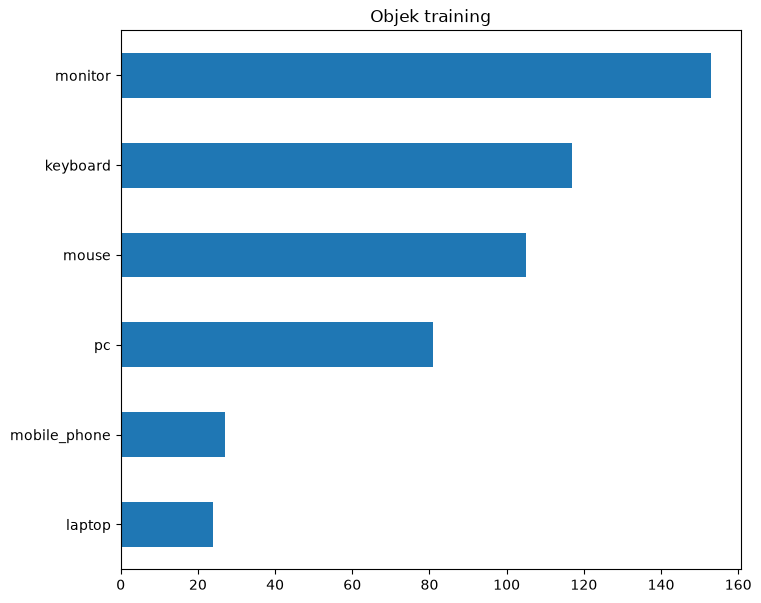

In [3]:
def baca_box(line):
    v=list(map(float,line.split()))
    if len(v)<5 or not all(np.isfinite(v)):
        raise ValueError('Anotasi tidak lengkap/nonfinite.')
    cid=int(v[0])
    if cid!=v[0] or not 0<=cid<len(source_names):raise ValueError('ID kelas tidak valid.')
    if not all(0<=z<=1 for z in v[1:]):raise ValueError('Koordinat harus 0-1.')
    if len(v)==5:
        x,y,w,h=v[1:]
    elif len(v)>=7 and (len(v)-1)%2==0:
        xs,ys=v[1::2],v[2::2]
        x,y=(min(xs)+max(xs))/2,(min(ys)+max(ys))/2
        w,h=max(xs)-min(xs),max(ys)-min(ys)
    else:raise ValueError('Format anotasi tidak valid.')
    if w<=0 or h<=0:raise ValueError('Box kosong.')
    if min(x-w/2,y-h/2)<-1e-6 or max(x+w/2,y+h/2)>1+1e-6:
        raise ValueError('Box keluar dari gambar.')
    return cid,x,y,w,h

ringkasan, distribusi = [], {}
for split in ['train', 'valid', 'test']:
    images = list((DATASET / split / 'images').glob('*.jpg'))
    counts = Counter()
    for image in images:
        label = DATASET / split / 'labels' / (image.stem+'.txt')
        assert label.exists(), f'Label hilang: {label}'
        for line in label.read_text().splitlines():
            if line.strip():
                cid=baca_box(line)[0]
                if cid in MAP_ID: counts[MAP_ID[cid]] += 1
    ringkasan.append({'split': split, 'gambar': len(images), 'objek': sum(counts.values())})
    distribusi[split] = {name: counts[i] for i,name in enumerate(names)}
display(pd.DataFrame(ringkasan))
display(pd.DataFrame(distribusi))
pd.Series(distribusi['train']).sort_values().plot.barh(figsize=(8,7), title='Objek training')
plt.show()

## 4. Visualisasi ground truth

**Tujuan:** Menampilkan contoh gambar train, valid, dan test beserta bounding box dan nama objek dari anotasinya.

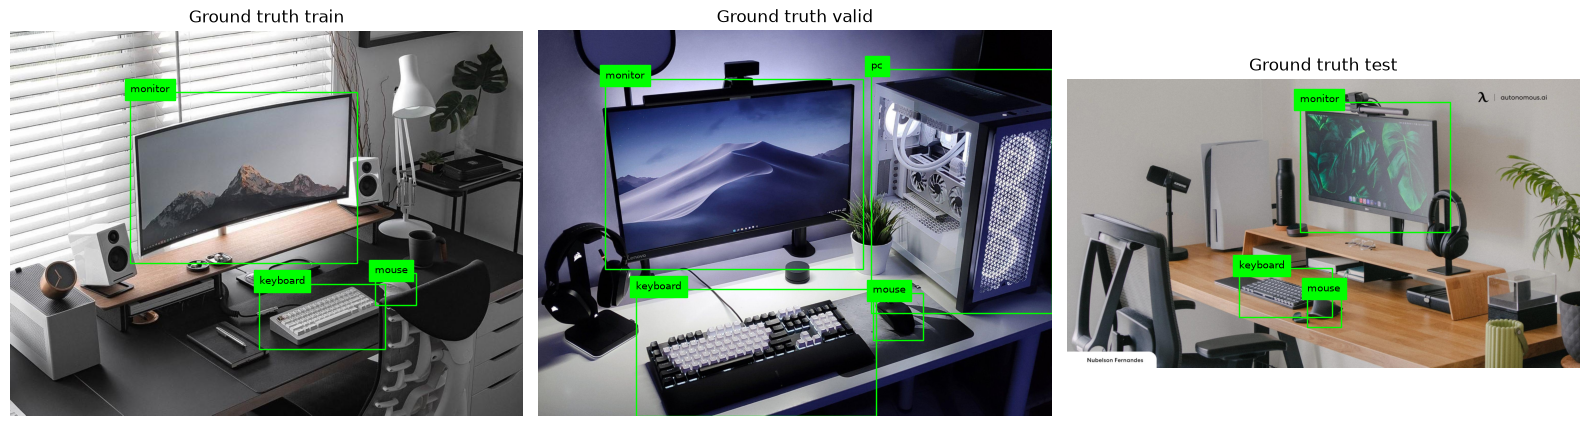

In [4]:
def tampil_label(path, ax):
    image = Image.open(path).convert('RGB')
    w, h = image.size
    ax.imshow(image)
    label = path.parent.parent / 'labels' / (path.stem+'.txt')
    for line in label.read_text().splitlines():
        if not line.strip(): continue
        cid,x,y,bw,bh = baca_box(line)
        if cid not in MAP_ID: continue
        cid=MAP_ID[cid]
        left,top = (x-bw/2)*w,(y-bh/2)*h
        ax.add_patch(Rectangle((left,top),bw*w,bh*h,fill=False,edgecolor='lime'))
        ax.text(left,top,names[cid],fontsize=7,backgroundcolor='lime')
    ax.axis('off')
fig,axes = plt.subplots(1,3,figsize=(16,5))
for ax,split in zip(axes,['train','valid','test']):
    path = sorted((DATASET/split/'images').glob('*.jpg'))[0]
    tampil_label(path,ax); ax.set_title('Ground truth '+split)
plt.tight_layout(); plt.show()

## 5. Pemeriksaan split

**Tujuan:** Menggunakan pembagian train/valid/test yang sudah tersedia dan memeriksa gambar rusak, duplikat identik, serta nama sumber yang muncul lintas split.

In [5]:
import hashlib
hashes,sources={},{}
for split in ['train','valid','test']:
    for image in (DATASET/split/'images').glob('*.jpg'):
        with Image.open(image) as pic:pic.verify()
        hashes.setdefault(hashlib.sha256(image.read_bytes()).hexdigest(),set()).add(split)
        sources.setdefault(image.name.split('.rf.')[0],set()).add(split)
assert not any(len(s)>1 for s in hashes.values()),'Duplikat identik lintas split.'
assert not any(len(s)>1 for s in sources.values()),'Nama sumber bocor lintas split.'
print('Audit split lolos: gambar terbaca, tidak ada duplikat identik/nama sumber lintas split.')

Audit split lolos: gambar terbaca, tidak ada duplikat identik/nama sumber lintas split.


## 6. Preprocessing dan training

**Tujuan:** menyaring anotasi menjadi enam kelas, memetakan ID ke 0?5 pada salinan sementara, dan melatih model. Gambar tanpa objek target tetap digunakan sebagai contoh background.

In [6]:
LATIH_MODEL = True  # Ubah False untuk evaluasi model Desktop Setup yang sudah tersimpan.

data_temp = tempfile.TemporaryDirectory(prefix='yolo11_dataset_')
work = Path(data_temp.name)
for split in ['train','valid','test']:
    (work/split/'images').mkdir(parents=True)
    (work/split/'labels').mkdir(parents=True)
    for image in (DATASET/split/'images').glob('*.jpg'):
        shutil.copy2(image,work/split/'images'/image.name)
        source_label = DATASET/split/'labels'/(image.stem+'.txt')
        rows=[]
        for line in source_label.read_text().splitlines():
            if line.strip():
                cid,x,y,w,h=baca_box(line)
                if cid in MAP_ID:
                    rows.append(f'{MAP_ID[cid]} {x:.8f} {y:.8f} {w:.8f} {h:.8f}')
        (work/split/'labels'/source_label.name).write_text('\n'.join(rows))
config={'path':work.as_posix(),'train':'train/images','val':'valid/images',
        'test':'test/images','names':names}
DATA_YAML=work/'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(config,sort_keys=False))
if LATIH_MODEL:
    calon=YOLO(str(BEST) if BEST.exists() else str(Path(runtime.name)/'weights/yolo11n.pt'))
    calon.train(data=str(DATA_YAML),epochs=80,patience=20,imgsz=640,batch=8,
                device=DEVICE,workers=0,seed=42,project=str(work/'runs'),name='latihan')
    BOBOT_BARU=Path(calon.trainer.save_dir)/'weights/best.pt'
    print('Training selesai. Lanjutkan evaluasi dan cell simpan model.')

New https://pypi.org/project/ultralytics/8.4.176 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.175  Python-3.12.10 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX A4000, 16376MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\GUMELAR AKHIRUL RAMADHAN\SEMESTER 5\Computer Vision\TUGAS\CODING\best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=latihan, nbs=64, nms=None, opset=None, 

Overriding model.yaml nc=15 with nc=6



                   from  n    params  module                                       arguments                     


...

                 mouse          8         10      0.872      0.681       0.67       0.38


                    pc          7          7          1      0.478      0.859      0.654


Speed: 0.6ms preprocess, 17.6ms inference, 0.0ms loss, 2.0ms postprocess per image


Results saved to C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\runs\latihan


Training selesai. Lanjutkan evaluasi dan cell simpan model.


## 7. Evaluasi dan pemilihan model

**Tujuan:** Menghitung Precision, Recall, mAP50, dan mAP50-95. Jika ada kandidat baru, pilih melalui validation sebelum mengevaluasi test. Tampilkan tabel, confusion matrix, dan PR curve untuk menilai hasil deteksi.

Metrik AP memakai confidence rendah untuk kurva. Matriks operasional pada langkah kalibrasi memakai confidence terpilih; kedua pengaturan memiliki tujuan berbeda.

Ultralytics 8.4.175  Python-3.12.10 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX A4000, 16376MiB)


YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 906.9457.4 MB/s, size: 260.3 KB)


val: Scanning C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\valid\labels.cache... 10 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10  0.0s

                   all         10         39      0.922      0.664      0.764      0.557


...

                 mouse          7          7      0.742      0.415        0.5      0.201


                    pc          6          6      0.941      0.833      0.922      0.723


Speed: 0.9ms preprocess, 24.2ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\evaluasi\test_semua


,model,split,kelas,Precision,Recall,mAP50,mAP50-95
0,kandidat_validation,val,6,0.9224,0.6644,0.7645,0.5574
1,test_semua,test,6,0.5399,0.5054,0.5450,0.3532


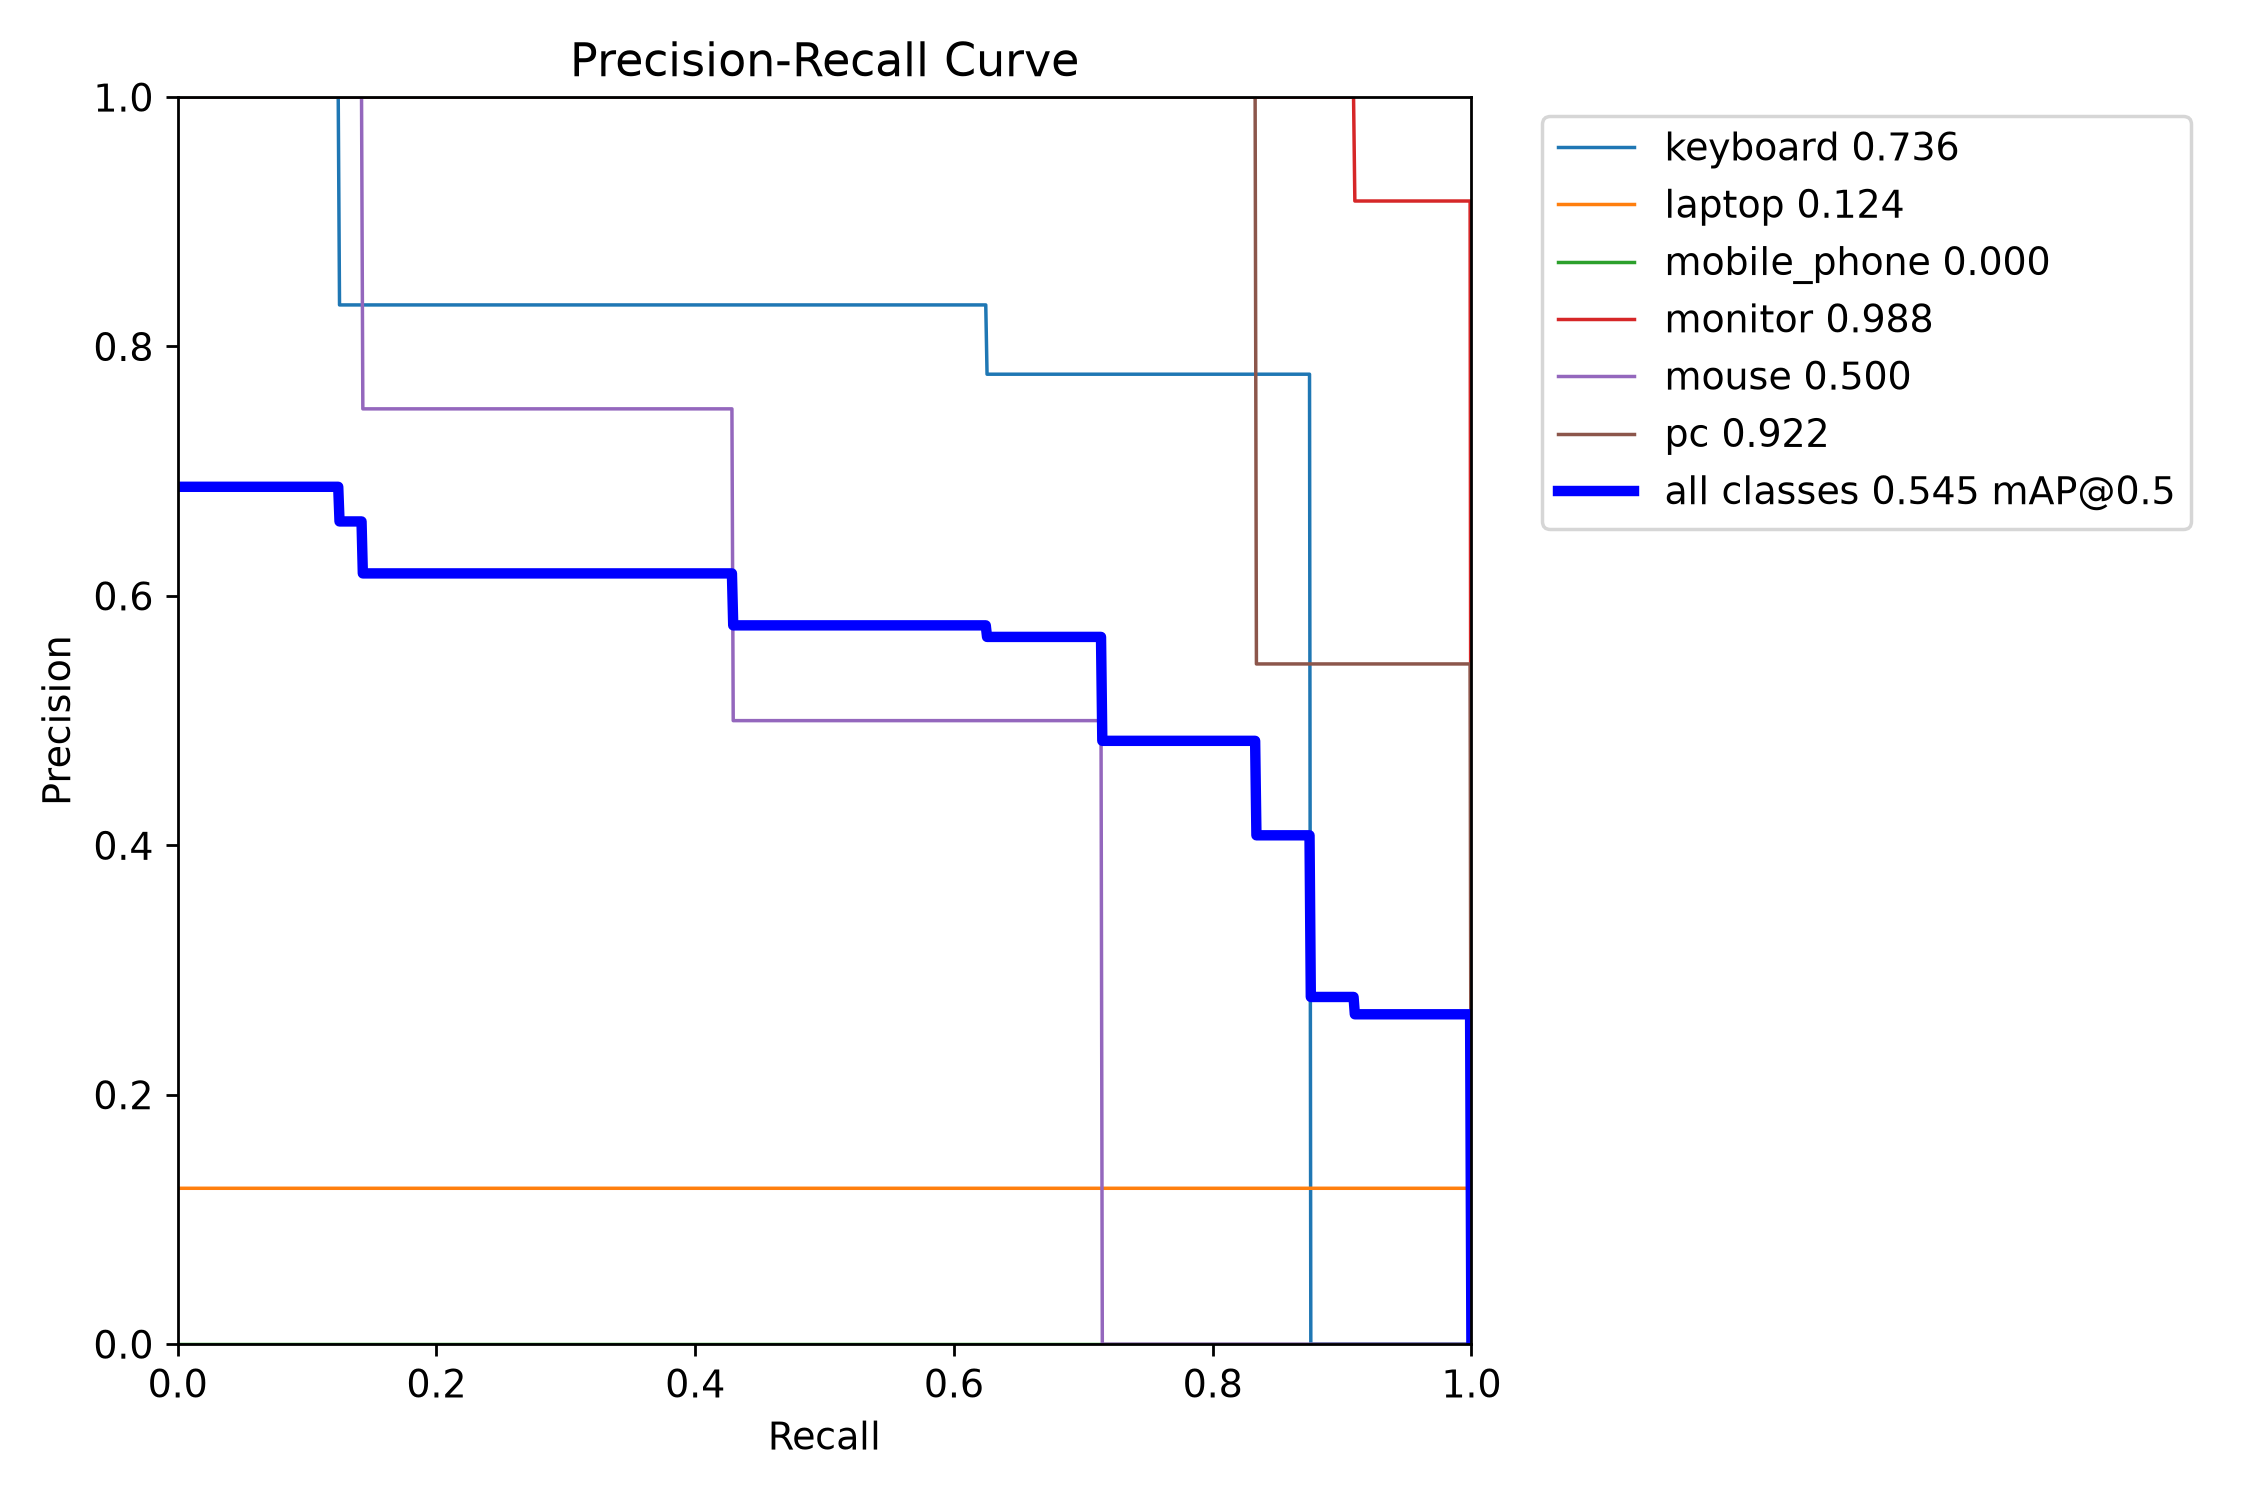

Bobot terpilih: C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\runs\latihan\weights\best.pt


In [7]:
rows=[]
def evaluasi(weights, split, label, classes=None):
    detector=YOLO(str(weights))
    metrics=detector.val(data=str(DATA_YAML),split=split,imgsz=640,batch=8,
        device=DEVICE,workers=0,classes=classes,plots=True,
        project=str(work/'evaluasi'),name=label)
    rows.append({'model':label,'split':split,'kelas':str(len(names)) if classes is None else f'{len(classes)} utama',
        'Precision':metrics.box.mp,'Recall':metrics.box.mr,
        'mAP50':metrics.box.map50,'mAP50-95':metrics.box.map})
    return metrics

TERPILIH=BEST
if LATIH_MODEL:
    baru=evaluasi(BOBOT_BARU,'val','kandidat_validation')
    if BEST.exists() and list(YOLO(str(BEST)).names.values()) == names:
        lama=evaluasi(BEST,'val','aktif_validation')
        if baru.box.map>=lama.box.map:TERPILIH=BOBOT_BARU
    else:TERPILIH=BOBOT_BARU
else:
    assert list(YOLO(str(BEST)).names.values()) == names, 'Aktifkan LATIH_MODEL untuk model Desktop Setup.'
    evaluasi(BEST,'val','aktif_validation')

model=YOLO(str(TERPILIH))
CLASS_IDS=list(model.names)  # Enam kelas terpilih Desktop Setup.
CONF=0.60
metrik=evaluasi(TERPILIH,'test','test_semua')
display(pd.DataFrame(rows).round(4))
for filename in ['BoxPR_curve.png']:
    image=Path(metrik.save_dir)/filename
    if image.exists():display(Image.open(image))
print('Bobot terpilih:',TERPILIH)

## Kalibrasi confidence pada validation Desktop Setup
**Tujuan:** memilih confidence untuk enam kelas Desktop Setup berdasarkan pasangan prediksi-ground truth (kelas sama, IoU minimal 0,50). Utamakan precision minimal 98%, lalu recall tertinggi. Bila target precision belum tercapai, gunakan F1 terbaik. Ini mengurangi false positive dengan kemungkinan lebih banyak objek terlewat.

,conf,TP,FP,FN,Precision,Recall,F1
0,0.4,25,3,14,0.8929,0.6410,0.7463
1,0.5,23,3,16,0.8846,0.5897,0.7077
2,0.6,22,3,17,0.8800,0.5641,0.6875
3,0.7,22,0,17,1.0000,0.5641,0.7213
4,0.8,19,0,20,1.0000,0.4872,0.6552


Confidence terpilih dari validation: 0.7
Ultralytics 8.4.175  Python-3.12.10 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX A4000, 16376MiB)


YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 818.1462.4 MB/s, size: 171.7 KB)


val: Scanning C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\test\labels.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8  0.0s

...

               monitor          7         11          1      0.909      0.905       0.72


                 mouse          7          7          1      0.143      0.145      0.102


                    pc          6          6          1      0.667      0.665      0.582


Speed: 0.3ms preprocess, 2.3ms inference, 0.0ms loss, 1.4ms postprocess per image


Results saved to C:\Users\student\AppData\Local\Temp\yolo11_dataset_f09myg3t\evaluasi\operasional


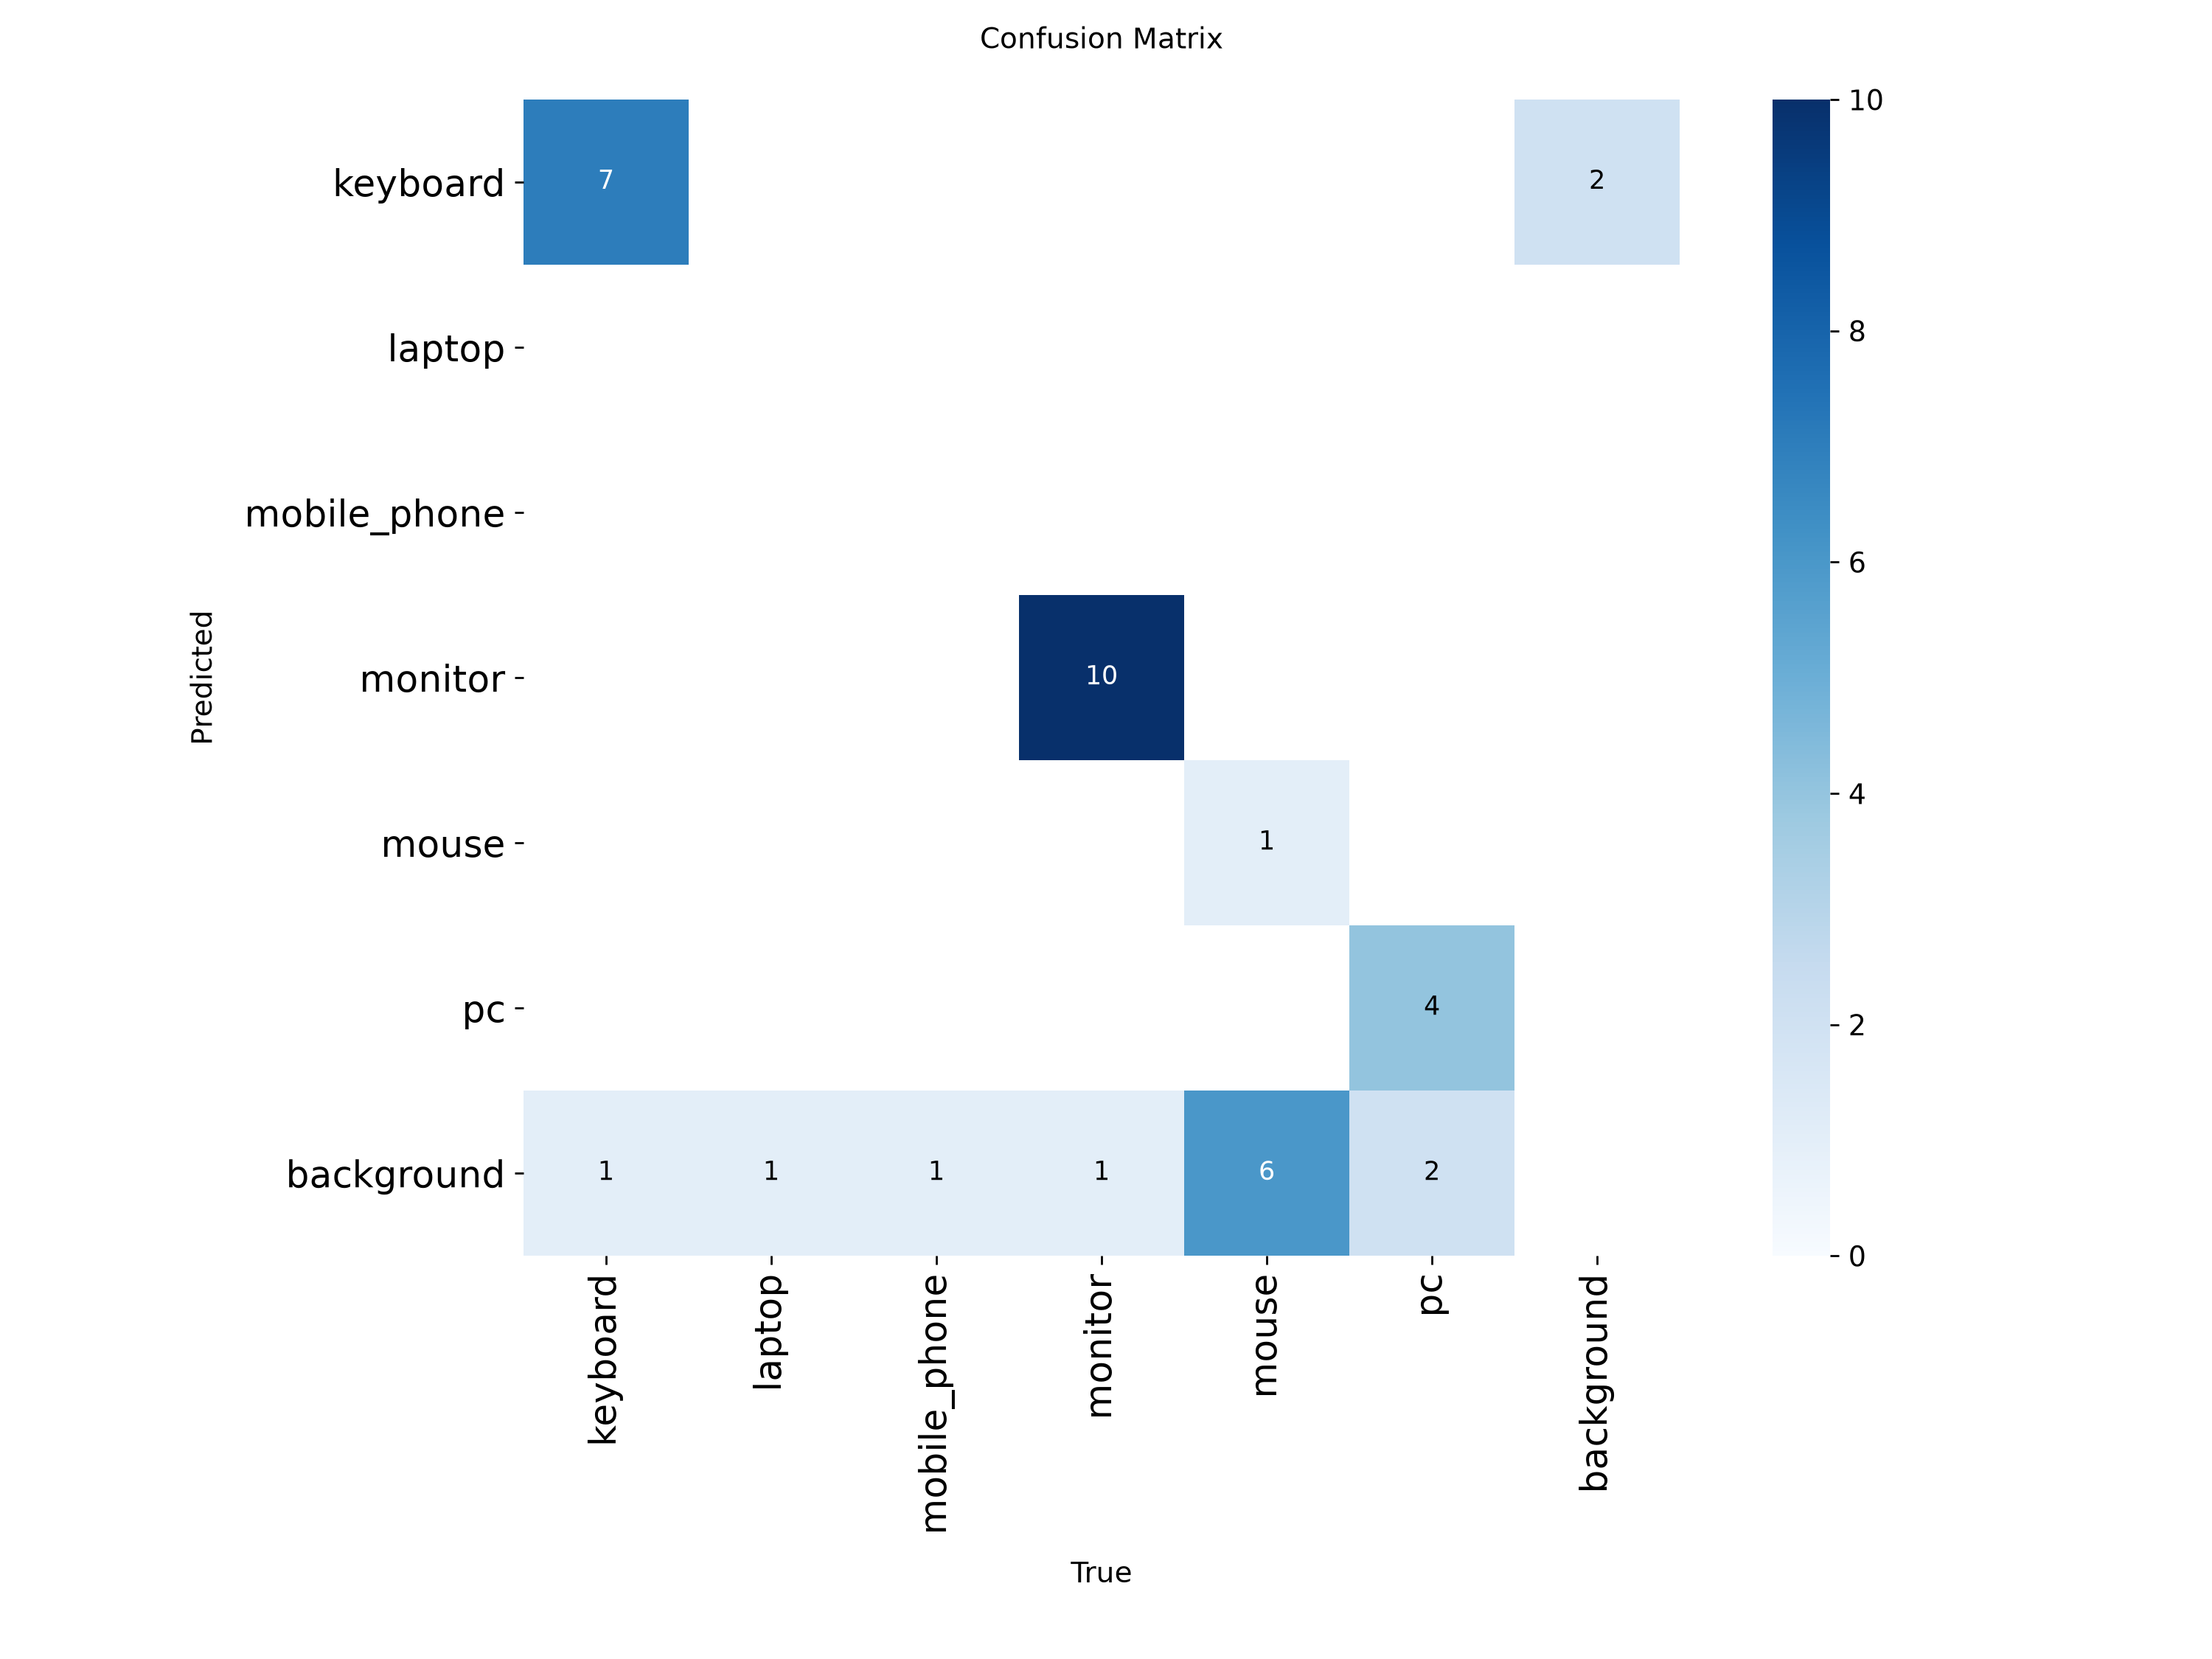

Matriks operasional: 0.7 | Matching IoU matriks: 0.45 (bawaan Ultralytics).


Confusion matrix validation: 6 kelas, confidence 0.7 dan matching IoU 0.50


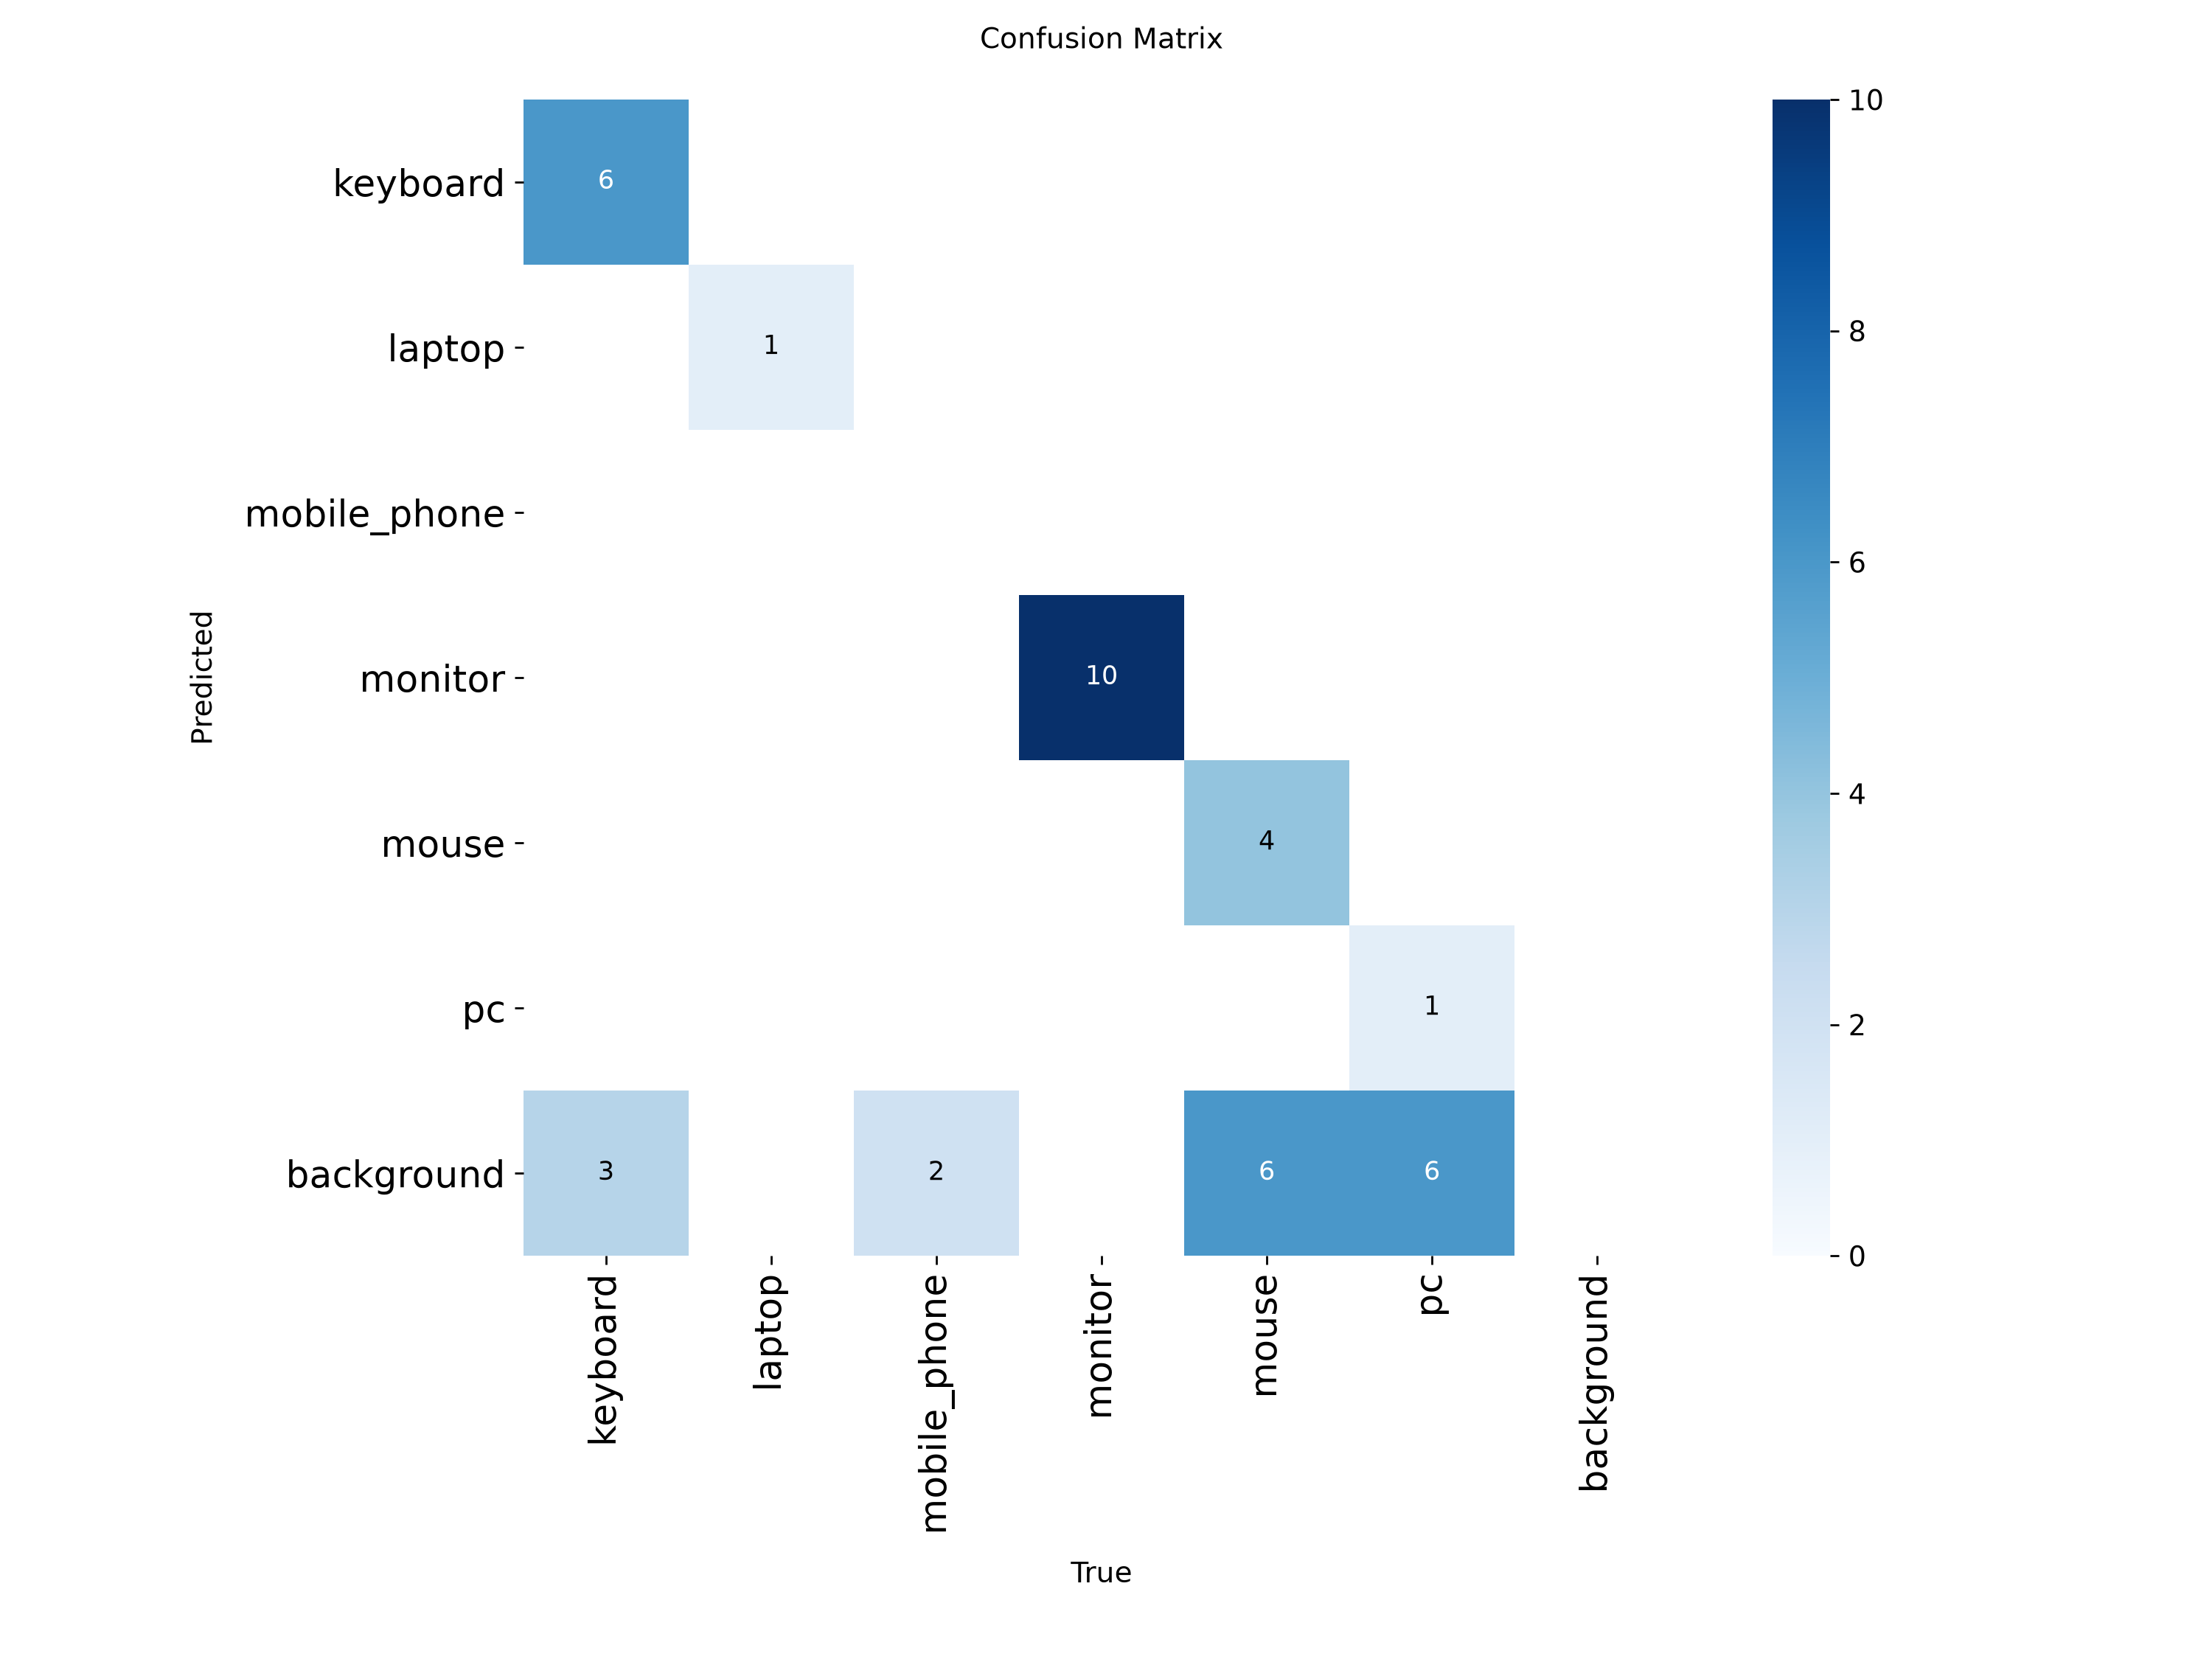

In [8]:
# Prediksi sekali, lalu bandingkan threshold menggunakan validation saja.
valid_images=sorted((work/'valid/images').glob('*.jpg'))
records=[]
for r in model.predict([str(p) for p in valid_images],conf=0.10,classes=CLASS_IDS,
                        iou=0.4,device=DEVICE,stream=True,batch=8,verbose=False):
    path=Path(r.path);w,h=Image.open(path).size
    truth=[]
    for line in (path.parent.parent/'labels'/(path.stem+'.txt')).read_text().splitlines():
        if not line.strip():continue
        cid,x,y,bw,bh=baca_box(line)
        if cid in CLASS_IDS:truth.append((cid,[(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h]))
    records.append((r.boxes.data.cpu().numpy(),truth))

def overlap(a,b):
    inter=max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
    return inter/max((a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter,1e-9)

calibration=[]
for threshold in [0.40,0.50,0.60,0.70,0.80]:
    tp=fp=fn=0
    for predictions,truth in records:
        used=set()
        for box in sorted(predictions[predictions[:,4]>=threshold],key=lambda b:-b[4]):
            matches=[(overlap(box[:4],gt),i) for i,(cid,gt) in enumerate(truth)
                     if cid==int(box[5]) and i not in used]
            score,i=max(matches,default=(0,-1))
            if score>=0.50:tp+=1;used.add(i)
            else:fp+=1
        fn+=len(truth)-len(used)
    precision=tp/max(tp+fp,1);recall=tp/max(tp+fn,1)
    calibration.append({'conf':threshold,'TP':tp,'FP':fp,'FN':fn,'Precision':precision,
                        'Recall':recall,'F1':2*precision*recall/max(precision+recall,1e-9)})
calibration=pd.DataFrame(calibration)
eligible=calibration[calibration.Precision>=0.98]
chosen=(eligible.sort_values(['Recall','Precision'],ascending=False) if len(eligible)
        else calibration.sort_values('F1',ascending=False)).iloc[0]
CONF=float(chosen['conf'])
display(calibration.round(4))
print('Confidence terpilih dari validation:',CONF)

# Grafik operasional memakai confidence yang sama dengan kamera, bukan threshold AP 0.001.
operasional=model.val(data=str(DATA_YAML),split='test',classes=CLASS_IDS,conf=CONF,
    iou=0.4,device=DEVICE,workers=0,batch=8,plots=True,
    project=str(work/'evaluasi'),name='operasional')
display(Image.open(Path(operasional.save_dir)/'confusion_matrix.png'))
print('Matriks operasional:',CONF,'| Matching IoU matriks: 0.45 (bawaan Ultralytics).')
# Matriks validation ringkas: kelas target dan background.
from ultralytics.utils.metrics import ConfusionMatrix
mapping={cid:i for i,cid in enumerate(CLASS_IDS)}
cm=ConfusionMatrix(names={i:model.names[cid] for cid,i in mapping.items()})
for predictions,truth in records:
    detections={'bboxes':torch.tensor(predictions[:,:4],dtype=torch.float32),
        'conf':torch.tensor(predictions[:,4],dtype=torch.float32),
        'cls':torch.tensor([mapping[int(cid)] for cid in predictions[:,5]],dtype=torch.float32)}
    batch={'bboxes':torch.tensor([box for cid,box in truth],dtype=torch.float32).reshape(-1,4),
        'cls':torch.tensor([mapping[cid] for cid,box in truth],dtype=torch.float32)}
    cm.process_batch(detections,batch,conf=CONF,iou_thres=0.50)
folder=work/'matrix_target_validation';folder.mkdir(exist_ok=True)
cm.plot(normalize=False,save_dir=folder)
print(f'Confusion matrix validation: {len(CLASS_IDS)} kelas, confidence',CONF,'dan matching IoU 0.50')
display(Image.open(folder/'confusion_matrix.png'))

## 8. Simpan model

**Tujuan:** Menyimpan bobot terpilih sebagai best.pt dan menyamakan default confidence kamera dengan hasil kalibrasi validation.

In [9]:
if Path(TERPILIH).resolve()!=BEST.resolve():
    shutil.copy2(TERPILIH,BEST)
assert BEST.is_file()
model=YOLO(str(BEST))
print('Model yang lolos pemilihan validation disimpan:',BEST.resolve())
script=BASE/'realtime_meja.py'
text=script.read_text(encoding='utf-8')
import re
text=re.sub(r"(parser.add_argument\('--conf',type=float,default=)[0-9.]+",lambda m:m.group(1)+f'{CONF:.2f}',text)
text=re.sub(r'(def kamera_iriun\(model, CLASS_IDS, DEVICE, conf=)[0-9.]+',lambda m:m.group(1)+f'{CONF:.2f}',text)
script.write_text(text,encoding='utf-8')
print('Default kamera disesuaikan:',CONF)

Model yang lolos pemilihan validation disimpan: D:\GUMELAR AKHIRUL RAMADHAN\SEMESTER 5\Computer Vision\TUGAS\CODING\best.pt
Default kamera disesuaikan: 0.7


## 9. Inference pada gambar test

**Tujuan:** Menampilkan bounding box, nama objek, dan confidence pada tiga gambar test untuk kelas target yang dipilih.

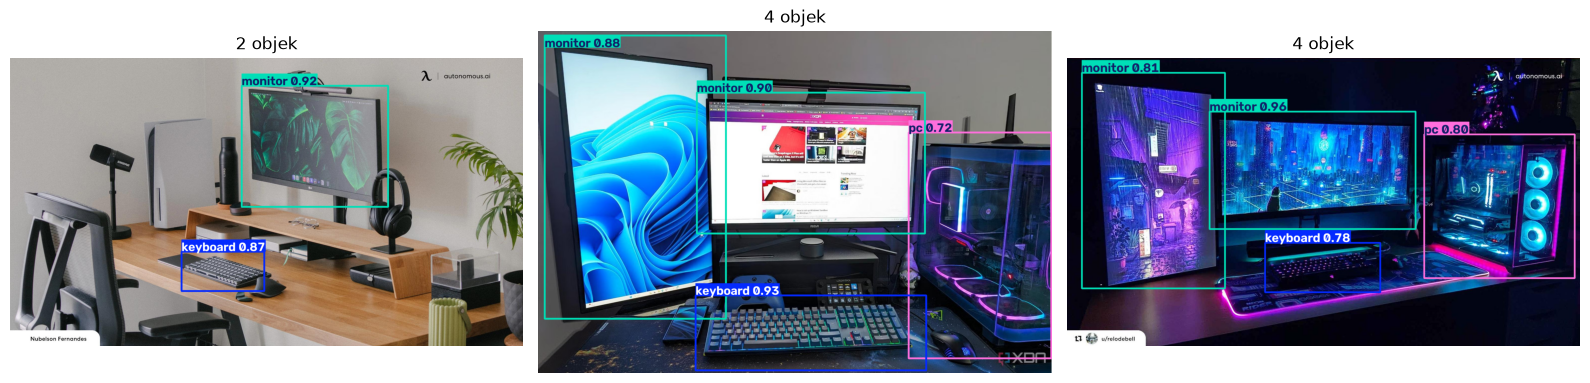

In [10]:
samples=sorted((DATASET/'test/images').glob('*.jpg'))[:3]
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,path in zip(axes,samples):
    result=model.predict(str(path),conf=CONF,classes=CLASS_IDS,device=DEVICE,verbose=False)[0]
    ax.imshow(result.plot()[...,::-1]);ax.set_title(f'{len(result.boxes)} objek');ax.axis('off')
plt.tight_layout();plt.show()

## 10. Eksperimen confidence

**Tujuan:** Membandingkan jumlah deteksi pada beberapa threshold untuk melihat pengaruh penyaringan prediksi.

In [11]:
image_valid=sorted((DATASET/'valid/images').glob('*.jpg'))[0]
for threshold in [0.25,0.40,0.60,0.75]:
    result=model.predict(str(image_valid),conf=threshold,classes=CLASS_IDS,device=DEVICE,verbose=False)[0]
    print(f'Confidence {threshold:.2f}: {len(result.boxes)} objek')

Confidence 0.25: 4 objek
Confidence 0.40: 3 objek
Confidence 0.60: 1 objek
Confidence 0.75: 1 objek


## 11. Deteksi foto sendiri

**Tujuan:** Mendeteksi objek pada foto yang ditentukan melalui FOTO, lalu menampilkan gambar hasil dan confidence setiap objek.

In [12]:
FOTO = None  # Contoh: Path('C:/Users/student/Downloads/foto_meja.jpg')
if FOTO is not None:
    result=model.predict(str(FOTO),conf=CONF,classes=CLASS_IDS,device=DEVICE,verbose=False)[0]
    plt.figure(figsize=(10,7));plt.imshow(result.plot()[...,::-1]);plt.axis('off');plt.show()
    display(pd.DataFrame([{'kelas':result.names[int(cid)],'confidence':round(float(c),3)}
                          for cid,c in zip(result.boxes.cls,result.boxes.conf)]))
else:
    print('Isi FOTO untuk mendeteksi foto sendiri.')

Isi FOTO untuk mendeteksi foto sendiri.


## 12. Jalankan kamera

**Tujuan:** memakai best.pt untuk mendeteksi objek dari kamera Iriun secara langsung.

Buka Iriun di PC dan HP, lalu jalankan di terminal folder CODING:

```powershell
python realtime_meja.py
```

Tekan **Q/Esc** untuk berhenti dan **+/-** untuk mengubah confidence.